Reciever Operating Characteristic Curve (ROC)


1)

Classifier C1 ROC Table:
 Threshold >=  TP  FP  TN  FN  TPR  FPR
         1.00   0   0   5   5  0.0  0.0
         0.95   1   0   5   4  0.2  0.0
         0.81   1   1   4   4  0.2  0.2
         0.77   2   1   4   3  0.4  0.2
         0.62   3   1   4   2  0.6  0.2
         0.40   3   2   3   2  0.6  0.4
         0.31   4   2   3   1  0.8  0.4
         0.30   4   3   2   1  0.8  0.6
         0.20   4   4   1   1  0.8  0.8
         0.15   5   4   1   0  1.0  0.8
         0.10   5   5   0   0  1.0  1.0

Classifier C1 AUC: 0.680

Classifier C2 ROC Table:
 Threshold >=  TP  FP  TN  FN  TPR  FPR
         1.00   0   0   5   5  0.0  0.0
         0.99   1   0   5   4  0.2  0.0
         0.70   2   0   5   3  0.4  0.0
         0.66   3   0   5   2  0.6  0.0
         0.65   4   0   5   1  0.8  0.0
         0.60   4   1   4   1  0.8  0.2
         0.55   4   2   3   1  0.8  0.4
         0.49   5   2   3   0  1.0  0.4
         0.35   5   3   2   0  1.0  0.6
         0.25   5   4   1   0  1.0  0.8
   

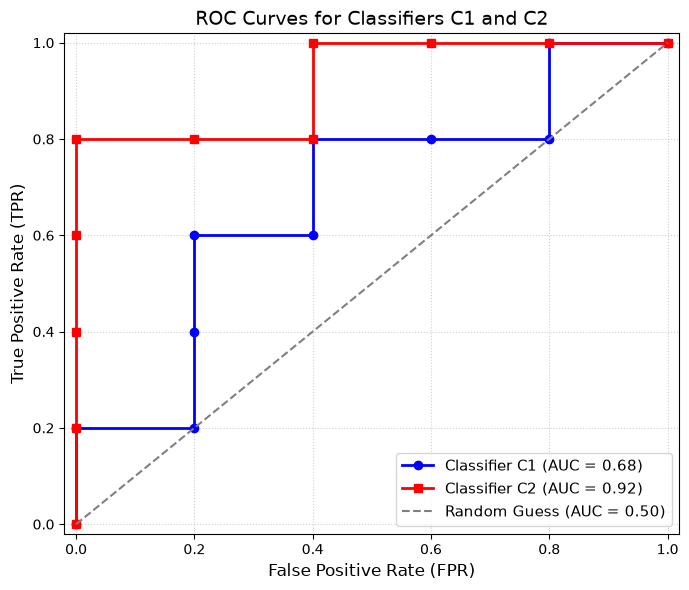

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Dataset
p_c1 = [0.10, 0.15, 0.20, 0.30, 0.31, 0.40, 0.62, 0.77, 0.81, 0.95]
p_c2 = [0.25, 0.49, 0.05, 0.35, 0.66, 0.60, 0.70, 0.65, 0.55, 0.99]
y_true = ["-", "+", "-", "-", "+", "-", "+", "+", "-", "+"]

# Convert true labels to binary
y_bin = np.array([1 if label == "+" else 0 for label in y_true])
P_total = np.sum(y_bin == 1)  # 5 positive instances
N_total = np.sum(y_bin == 0)  # 5 negative instances


# 2. Compute ROC points
def compute_roc_table(scores, y_true_bin):
    # Distinct threshold values sorted descending, plus a threshold > max to get (0, 0)
    thresholds = [1.0] + sorted(list(set(scores)), reverse=True)

    records = []
    for t in thresholds:
        # Predict positive if score >= t
        y_pred = (scores >= t).astype(int)

        tp = np.sum((y_pred == 1) & (y_true_bin == 1))
        fp = np.sum((y_pred == 1) & (y_true_bin == 0))
        tn = np.sum((y_pred == 0) & (y_true_bin == 0))
        fn = np.sum((y_pred == 0) & (y_true_bin == 1))

        tpr = tp / P_total
        fpr = fp / N_total

        records.append(
            {
                "Threshold >=": t,
                "TP": tp,
                "FP": fp,
                "TN": tn,
                "FN": fn,
                "TPR": tpr,
                "FPR": fpr,
            }
        )

    df = pd.DataFrame(records)
    # Ensure (0,0) and (1,1) endpoints exist
    fprs = df["FPR"].tolist()
    tprs = df["TPR"].tolist()
    if fprs[-1] != 1.0 or tprs[-1] != 1.0:
        fprs.append(1.0)
        tprs.append(1.0)

    # Compute trapezoidal AUC
    auc = np.trapezoid(tprs, fprs)
    return df, fprs, tprs, auc


# Compute tables and curves for both classifiers
df_c1, fpr_c1, tpr_c1, auc_c1 = compute_roc_table(np.array(p_c1), y_bin)
df_c2, fpr_c2, tpr_c2, auc_c2 = compute_roc_table(np.array(p_c2), y_bin)

pd.set_option('display.max_rows', None)
print("Classifier C1 ROC Table:")
print(df_c1.to_string(index=False))
print(f"\nClassifier C1 AUC: {auc_c1:.3f}\n")


print("Classifier C2 ROC Table:")
print(df_c2.to_string(index=False))
print(f"\nClassifier C2 AUC: {auc_c2:.3f}\n")

# 3. Plot ROC Curves
plt.figure(figsize=(7, 6))
plt.step(
    fpr_c1,
    tpr_c1,
    where="post",
    label=f"Classifier C1 (AUC = {auc_c1:.2f})",
    color="blue",
    linewidth=2,
    marker="o",
)
plt.step(
    fpr_c2,
    tpr_c2,
    where="post",
    label=f"Classifier C2 (AUC = {auc_c2:.2f})",
    color="red",
    linewidth=2,
    marker="s",
)
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Random Guess (AUC = 0.50)",
)

plt.title("ROC Curves for Classifiers C1 and C2", fontsize=14)
plt.xlabel("False Positive Rate (FPR)", fontsize=12)
plt.ylabel("True Positive Rate (TPR)", fontsize=12)
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.show()

2) Classifier C2 is considered better because the AUC is larger at $0.92$, compared to only $0.68$ for Classifier C1.